In [1]:
#loading and setting up the model:
import pandas as pd, numpy as np
from sklearn.model_selection import TimeSeriesSplit, cross_validate
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.dummy import DummyClassifier

train = pd.read_csv("../data/train_processed.csv", parse_dates=["dt"]).sort_values("dt").reset_index(drop=True)
test = pd.read_csv("../data/test_processed.csv", parse_dates=["dt"])

features = [c for c in train.columns if c not in ["dt", "target"]]
X_train, y_train = train[features], train["target"]
X_test, y_test = test[features], test["target"]

rows_per_day = int(train.groupby("dt").size().median())
cv = TimeSeriesSplit(n_splits=5, gap=3 * rows_per_day)
print(len(features), "features")

45 features


In [2]:
#cross-validating 3 models and a baseline:

models = {
    "Baseline (always 0)": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Random Forest": RandomForestClassifier(n_estimators=100, max_depth=10, n_jobs=-1, random_state=42),
    "Gradient Boosting": HistGradientBoostingClassifier(random_state=42),
}
scoring = ["accuracy", "precision", "recall", "f1", "roc_auc"]

rows = []
for name, m in models.items():
    r = cross_validate(m, X_train, y_train, cv=cv, scoring=scoring)
    rows.append({"model": name, **{k: r[f"test_{k}"].mean() for k in scoring}})
results = pd.DataFrame(rows).set_index("model").round(3)
results

c:\Users\lyba6\UNI PROJECTS\stockout-alerter\venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\lyba6\UNI PROJECTS\stockout-alerter\venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\lyba6\UNI PROJECTS\stockout-alerter\venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()}

,accuracy,precision,recall,f1,roc_auc
model,,,,,
Baseline (always 0),0.604,0.077,0.200,0.112,0.500
Logistic Regression,0.637,0.551,0.364,0.379,0.616
Random Forest,0.665,0.608,0.305,0.362,0.649
Gradient Boosting,0.651,0.538,0.366,0.401,0.641


In [3]:
#hyperparameter tuning:

from sklearn.model_selection import GridSearchCV

configs = {
    "Logistic Regression": (LogisticRegression(max_iter=2000, class_weight="balanced"),
                            {"C": [0.01, 0.1, 1, 10]}),
    "Random Forest": (RandomForestClassifier(n_estimators=100, class_weight="balanced_subsample",
                                             n_jobs=-1, random_state=42),
                      {"max_depth": [6, 10, 15], "min_samples_leaf": [20, 50]}),
    "Gradient Boosting": (HistGradientBoostingClassifier(class_weight="balanced", random_state=42),
                          {"learning_rate": [0.05, 0.1], "max_depth": [3, 6], "max_iter": [100, 200]}),
}

searches = {}
for name, (model, grid) in configs.items():
    s = GridSearchCV(model, grid, cv=cv, scoring="roc_auc", n_jobs=1)
    s.fit(X_train, y_train)
    searches[name] = s
    print(f"{name}: best CV AUC={s.best_score_:.3f}, params={s.best_params_}")

Logistic Regression: best CV AUC=0.621, params={'C': 0.01}
Random Forest: best CV AUC=0.652, params={'max_depth': 10, 'min_samples_leaf': 20}
Gradient Boosting: best CV AUC=0.647, params={'learning_rate': 0.05, 'max_depth': 6, 'max_iter': 100}


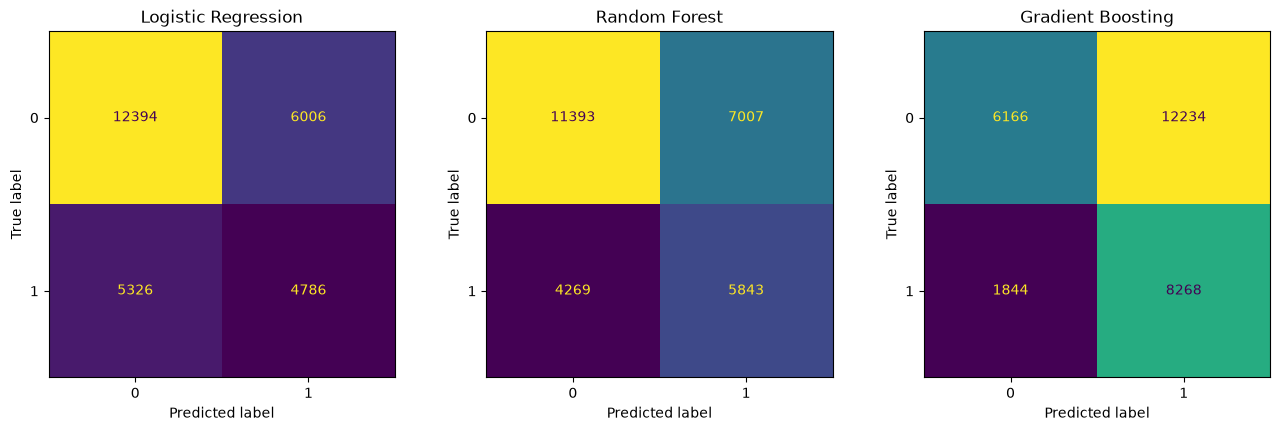

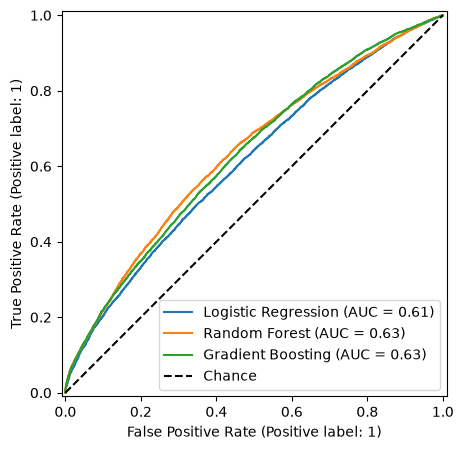

,accuracy,precision,recall,f1,test_auc,train_auc,cv_auc
model,,,,,,,
Logistic Regression,0.603,0.443,0.473,0.458,0.609,0.673,0.621
Random Forest,0.605,0.455,0.578,0.509,0.634,0.729,0.652
Gradient Boosting,0.506,0.403,0.818,0.540,0.629,0.727,0.647


Saved: Random Forest


In [4]:
#final test evaluation, plots, and save the best model:

from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, ConfusionMatrixDisplay, RocCurveDisplay)
import matplotlib.pyplot as plt, joblib

rows = []
fig1, ax1 = plt.subplots(1, 3, figsize=(16, 4.5))
fig2, ax2 = plt.subplots(figsize=(6, 5))
for i, (name, s) in enumerate(searches.items()):
    m = s.best_estimator_
    pred, proba = m.predict(X_test), m.predict_proba(X_test)[:, 1]
    rows.append({"model": name,
                 "accuracy": accuracy_score(y_test, pred),
                 "precision": precision_score(y_test, pred),
                 "recall": recall_score(y_test, pred),
                 "f1": f1_score(y_test, pred),
                 "test_auc": roc_auc_score(y_test, proba),
                 "train_auc": roc_auc_score(y_train, m.predict_proba(X_train)[:, 1]),
                 "cv_auc": s.best_score_})
    ConfusionMatrixDisplay.from_predictions(y_test, pred, ax=ax1[i], colorbar=False)
    ax1[i].set_title(name)
    RocCurveDisplay.from_predictions(y_test, proba, ax=ax2, name=name)
ax2.plot([0, 1], [0, 1], "k--", label="Chance")
ax2.legend()
fig1.savefig("../report/confusion_matrices.png", dpi=150, bbox_inches="tight")
fig2.savefig("../report/roc_curves.png", dpi=150, bbox_inches="tight")
plt.show()

final = pd.DataFrame(rows).set_index("model").round(3)
display(final)

# Pick the winner by CV score (not test score) and save it for the API
best_name = max(searches, key=lambda k: searches[k].best_score_)
joblib.dump(searches[best_name].best_estimator_, "../app/model.joblib")
joblib.dump(features, "../app/features.joblib")
print("Saved:", best_name)